# Smart Dice Board Game: Reinforcement Learning (Phase 2)
### Tabular & Deep RL Benchmarking: Q-Learning, SARSA, DQN, PPO, and A2C

This notebook executes Phase 2 of the Smart Dice Reinforcement Learning course project.
It trains, evaluates, and compares **five reinforcement learning algorithms** across three board configurations ($N=30, 50, 100$) using **Breadth-First Search (BFS)** as the optimal deterministic baseline.

---

### Key Requirements Addressed:
1. **Kaggle-Ready**: Includes the Smart Dice package source. Run all cells on Kaggle or in a local Jupyter kernel.
2. **Deterministic Baseline**: Finds the shortest path on each board using BFS.
3. **Five RL Algorithms**:
   - Tabular Q-Learning (Off-policy TD)
   - Tabular SARSA (On-policy TD)
   - Deep Q-Network (DQN with Experience Replay & Target Network)
   - Proximal Policy Optimization (PPO with Clipped Surrogate Objective)
   - Advantage Actor-Critic (A2C with Synchronous Advantage Updates)
4. **Unified Evaluator**: Same evaluation pipeline across all algorithms reporting average moves, success rate, return, and convergence episode.
5. **Artifacts & Plots**: Saves all trained models, evaluation metrics CSV, and five publication-quality plots under `artifacts/` (or `/kaggle/working/artifacts`).


In [1]:
from importlib.util import find_spec
from pathlib import Path
import os
import subprocess
import sys

missing = [
    package for package in ("gymnasium", "stable_baselines3", "torch", "numpy", "matplotlib", "pandas")
    if find_spec(package) is None
]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Small MLPs and single-environment rollouts run efficiently on one CPU thread.
torch.set_num_threads(1)

KAGGLE_WORKING_DIR = Path("/kaggle/working")
WORKING_DIR = KAGGLE_WORKING_DIR if KAGGLE_WORKING_DIR.is_dir() else Path.cwd()
ARTIFACTS_DIR = WORKING_DIR / "artifacts"
PACKAGE_DIR = WORKING_DIR / ".phase2_package"
for directory in ("envs", "baselines", "training"):
    (PACKAGE_DIR / "smart_dice" / directory).mkdir(parents=True, exist_ok=True)


## Embedded Smart Dice package

The following cells write the package used by this notebook into the working directory.

In [2]:
%%writefile "{PACKAGE_DIR}/smart_dice/__init__.py"
"""Smart Dice Board Game Gymnasium Environment and Baselines."""

from smart_dice.envs.board_config import (
    BoardConfig,
    BOARD_CONFIG_30,
    BOARD_CONFIG_50,
    BOARD_CONFIG_100,
    BOARD_CONFIG_100_ASSIGNMENT,
    BOARD_CONFIGS,
    detect_positive_reward_cycle,
    get_board_config,
)
from smart_dice.envs.smart_dice_env import SmartDiceEnv
from smart_dice.baselines.bfs import BFSResult, bfs_shortest_path, solve_bfs
from smart_dice.training import (
    determine_convergence,
    evaluate_agent,
    extract_action_from_agent,
    train_q_learning,
    train_sarsa,
    EpisodeMetricsCallback,
)

__all__ = [
    "BoardConfig",
    "SmartDiceEnv",
    "BOARD_CONFIG_30",
    "BOARD_CONFIG_50",
    "BOARD_CONFIG_100",
    "BOARD_CONFIG_100_ASSIGNMENT",
    "BOARD_CONFIGS",
    "detect_positive_reward_cycle",
    "get_board_config",
    "BFSResult",
    "bfs_shortest_path",
    "solve_bfs",
    "determine_convergence",
    "evaluate_agent",
    "extract_action_from_agent",
    "train_q_learning",
    "train_sarsa",
    "EpisodeMetricsCallback",
]


Writing /kaggle/working/.phase2_package/smart_dice/__init__.py


In [3]:
%%writefile "{PACKAGE_DIR}/smart_dice/envs/__init__.py"
"""Environment package for Smart Dice Board Game."""

from smart_dice.envs.board_config import (
    BoardConfig,
    BOARD_CONFIG_30,
    BOARD_CONFIG_50,
    BOARD_CONFIG_100,
    BOARD_CONFIG_100_ASSIGNMENT,
    BOARD_CONFIGS,
    detect_positive_reward_cycle,
    get_board_config,
)
from smart_dice.envs.smart_dice_env import SmartDiceEnv

__all__ = [
    "BoardConfig",
    "BOARD_CONFIG_30",
    "BOARD_CONFIG_50",
    "BOARD_CONFIG_100",
    "BOARD_CONFIG_100_ASSIGNMENT",
    "BOARD_CONFIGS",
    "detect_positive_reward_cycle",
    "get_board_config",
    "SmartDiceEnv",
]


Writing /kaggle/working/.phase2_package/smart_dice/envs/__init__.py


In [4]:
%%writefile "{PACKAGE_DIR}/smart_dice/envs/board_config.py"
"""Board configurations for the Smart Dice Board Game."""

from __future__ import annotations

from dataclasses import dataclass, field
from typing import Any, Dict, List, Optional, Tuple, Union
import numpy as np


def detect_positive_reward_cycle(
    n: int,
    snakes: Dict[int, int],
    ladders: Dict[int, int],
) -> Tuple[bool, Optional[List[int]], float]:
    """Detect if the deterministic board graph contains a cycle with net positive reward.

    Uses the Bellman-Ford algorithm on the inverted-reward graph (weight = -reward).
    A negative weight cycle in this graph corresponds to a positive reward cycle.

    Returns:
        (has_cycle, cycle_nodes, net_cycle_reward)
    """
    nodes = list(range(1, n))
    edges: List[Tuple[int, int, float, float, int]] = []

    # Build directed transitions for actions 0..5 (dice values 1..6)
    for u in nodes:
        for d in range(1, 7):
            t = u + d
            if t > n:
                v = u
                r = -10.0  # REWARD_INVALID
            elif t == n:
                continue  # Reaching goal terminates the episode, cannot be part of a cycle
            elif t in ladders:
                dest = ladders[t]
                if dest == n:
                    continue  # Terminal ladder
                v = dest
                r = 20.0  # REWARD_LADDER
            elif t in snakes:
                dest = snakes[t]
                if dest == n:
                    continue  # Terminal snake
                v = dest
                r = -20.0  # REWARD_SNAKE
            else:
                v = t
                r = -1.0  # REWARD_NORMAL

            # weight = -reward; finding negative cycle is equivalent to finding positive reward cycle
            edges.append((u, v, -r, r, d))

    dist: Dict[int, float] = {u: 0.0 for u in nodes}
    pred: Dict[int, Optional[Tuple[int, float, int]]] = {u: None for u in nodes}

    # Relax edges |V| - 1 times
    for _ in range(len(nodes) - 1):
        updated = False
        for u, v, w, r, d in edges:
            if dist[u] + w < dist[v] - 1e-9:
                dist[v] = dist[u] + w
                pred[v] = (u, r, d)
                updated = True
        if not updated:
            return False, None, 0.0

    # Check for negative weight cycle
    for u, v, w, r, d in edges:
        if dist[u] + w < dist[v] - 1e-9:
            # Trace back to isolate cycle nodes
            curr = v
            for _ in range(len(nodes)):
                assert pred[curr] is not None
                curr = pred[curr][0]

            cycle_nodes = [curr]
            cycle_reward = 0.0
            while True:
                step_info = pred[cycle_nodes[-1]]
                assert step_info is not None
                prev_node, r_step, _ = step_info
                cycle_reward += r_step
                cycle_nodes.append(prev_node)
                if prev_node == curr:
                    break
            cycle_nodes.reverse()
            return True, cycle_nodes, cycle_reward

    return False, None, 0.0


def _validate_int_coord(val: Any, role: str) -> int:
    """Validate that coordinate is strictly an integer (reject bools, floats, strings)."""
    if isinstance(val, bool):
        raise TypeError(f"{role} cannot be a boolean (got {val!r})")
    if not isinstance(val, (int, np.integer)):
        raise TypeError(
            f"{role} must be an integer, got {val!r} of type {type(val).__name__}"
        )
    return int(val)


@dataclass
class BoardConfig:
    """Configuration class for the Smart Dice Board Game.

    Attributes:
        n: Total number of squares on the board (from 1 to n).
        snakes: Mapping of snake start square to snake tail square (start > tail).
        ladders: Mapping of ladder base square to ladder top square (base < top).
        max_steps: Maximum number of allowed steps in an episode before truncation.
        name: A human-readable identifier for this configuration.
        allow_positive_reward_cycles: If False, raises ValueError if a positive reward cycle exists.
    """

    n: int
    snakes: Dict[int, int] = field(default_factory=dict)
    ladders: Dict[int, int] = field(default_factory=dict)
    max_steps: int = 1000
    name: str = "custom"
    allow_positive_reward_cycles: bool = False

    def __post_init__(self) -> None:
        self.validate()

    def validate(self) -> None:
        """Validate board parameters, types, coordinate rules, and cycle safety."""
        self.n = _validate_int_coord(self.n, "Board size n")
        if self.n < 2:
            raise ValueError(f"Board size n must be an integer >= 2, got {self.n}")

        self.max_steps = _validate_int_coord(self.max_steps, "max_steps")
        if self.max_steps <= 0:
            raise ValueError(f"max_steps must be a positive integer, got {self.max_steps}")

        # Validate ladders (types and bounds)
        sanitized_ladders: Dict[int, int] = {}
        for start, end in self.ladders.items():
            start_int = _validate_int_coord(start, "Ladder start square")
            end_int = _validate_int_coord(end, "Ladder end square")
            if not (1 < start_int < end_int <= self.n):
                raise ValueError(
                    f"Invalid ladder ({start_int} -> {end_int}): must satisfy 1 < start < end <= {self.n}"
                )
            sanitized_ladders[start_int] = end_int

        # Validate snakes (types and bounds)
        sanitized_snakes: Dict[int, int] = {}
        for start, end in self.snakes.items():
            start_int = _validate_int_coord(start, "Snake start square")
            end_int = _validate_int_coord(end, "Snake end square")
            if not (1 <= end_int < start_int < self.n):
                raise ValueError(
                    f"Invalid snake ({start_int} -> {end_int}): must satisfy 1 <= end < start < {self.n}"
                )
            sanitized_snakes[start_int] = end_int

        # Ensure disjoint start squares for snakes and ladders
        overlap = set(sanitized_snakes.keys()).intersection(set(sanitized_ladders.keys()))
        if overlap:
            raise ValueError(f"Squares cannot be both snake and ladder starts: {overlap}")

        self.snakes = sanitized_snakes
        self.ladders = sanitized_ladders

        # Check for positive reward cycles
        if not self.allow_positive_reward_cycles:
            has_cycle, cycle_nodes, cycle_reward = detect_positive_reward_cycle(
                self.n, self.snakes, self.ladders
            )
            if has_cycle and cycle_nodes is not None:
                cycle_str = " -> ".join(map(str, cycle_nodes))
                raise ValueError(
                    f"Board '{self.name}' contains a positive reward cycle: "
                    f"{cycle_str} (net reward: {cycle_reward:+.1f}). "
                    f"Positive reward cycles must be prevented to avoid infinite learning loops."
                )


# Configuration 1: N=30, 3 snakes, 3 ladders (Loop-safe)
BOARD_CONFIG_30 = BoardConfig(
    n=30,
    snakes={
        14: 4,
        21: 9,
        27: 7,
    },
    ladders={
        3: 12,
        8: 18,
        15: 24,
    },
    max_steps=500,
    name="board_30",
)

# Configuration 2: N=50, 5 snakes, 5 ladders (Loop-safe)
BOARD_CONFIG_50 = BoardConfig(
    n=50,
    snakes={
        17: 6,
        25: 10,
        34: 16,
        43: 22,
        48: 26,
    },
    ladders={
        4: 14,
        12: 28,
        20: 36,
        29: 42,
        37: 47,
    },
    max_steps=1000,
    name="board_50",
)

# Configuration 3: N=100, 8 snakes, 8 ladders (Loop-safe default)
BOARD_CONFIG_100 = BoardConfig(
    n=100,
    snakes={
        31: 9,
        45: 16,
        58: 32,
        67: 43,
        77: 65,
        86: 66,
        93: 74,
        97: 85,
    },
    ladders={
        4: 25,
        13: 39,
        28: 55,
        41: 62,
        54: 76,
        63: 84,
        72: 91,
        80: 96,
    },
    max_steps=2000,
    name="board_100",
)

# Documented assignment board containing the +40 exploit cycle:
# 84 -> 52 -> 76 -> 96 -> 40 -> 62 -> 84 (worth +40 every 6 moves)
BOARD_CONFIG_100_ASSIGNMENT = BoardConfig(
    n=100,
    snakes={
        31: 9,
        45: 16,
        58: 23,
        67: 38,
        78: 44,
        88: 52,
        93: 65,
        98: 40,
    },
    ladders={
        4: 25,
        13: 39,
        28: 55,
        41: 62,
        54: 76,
        63: 84,
        72: 91,
        80: 96,
    },
    max_steps=2000,
    name="board100_assignment",
    allow_positive_reward_cycles=True,
)

BOARD_CONFIGS: Dict[str, BoardConfig] = {
    "30": BOARD_CONFIG_30,
    "board_30": BOARD_CONFIG_30,
    "small": BOARD_CONFIG_30,
    "50": BOARD_CONFIG_50,
    "board_50": BOARD_CONFIG_50,
    "medium": BOARD_CONFIG_50,
    "100": BOARD_CONFIG_100,
    "board_100": BOARD_CONFIG_100,
    "large": BOARD_CONFIG_100,
    "board100_assignment": BOARD_CONFIG_100_ASSIGNMENT,
    "board_100_assignment": BOARD_CONFIG_100_ASSIGNMENT,
    "exploit": BOARD_CONFIG_100_ASSIGNMENT,
}


def get_board_config(identifier: Union[int, str, BoardConfig]) -> BoardConfig:
    """Retrieve a BoardConfig instance from integer, name, or pass-through existing BoardConfig."""
    if isinstance(identifier, BoardConfig):
        return identifier
    key = str(identifier).lower()
    if key in BOARD_CONFIGS:
        return BOARD_CONFIGS[key]
    raise KeyError(
        f"Unknown board configuration '{identifier}'. Available presets: {list(BOARD_CONFIGS.keys())}"
    )


Writing /kaggle/working/.phase2_package/smart_dice/envs/board_config.py


In [5]:
%%writefile "{PACKAGE_DIR}/smart_dice/envs/smart_dice_env.py"
"""Smart Dice Board Game Gymnasium Environment."""

from __future__ import annotations

from typing import Any, Dict, Optional, Tuple, Union
import gymnasium as gym
from gymnasium import spaces

from smart_dice.envs.board_config import BoardConfig, BOARD_CONFIG_30, get_board_config


class SmartDiceEnv(gym.Env):
    """Smart Dice Board Game Gymnasium Environment.

    A controllable board game where an agent chooses an action in {0, 1, 2, 3, 4, 5}
    which maps to dice values 1 through 6:
        dice_value = action + 1

    State / Observation Space:
        `gymnasium.spaces.Discrete(N + 1)`
        The agent's current square position is an integer in {1, 2, ..., N}.
        Index 0 is unused. `observation_space.contains(obs)` is True for all valid positions.

    Action Space:
        `gymnasium.spaces.Discrete(6)`
        Valid actions are integers in {0, 1, 2, 3, 4, 5}.
        - action 0 -> dice value 1
        - action 1 -> dice value 2
        - action 2 -> dice value 3
        - action 3 -> dice value 4
        - action 4 -> dice value 5
        - action 5 -> dice value 6

    Reward Structure:
        - Reach the final square N: +100
        - Land on a ladder: +20 (agent teleports forward to ladder top)
        - Land on a normal square: -1
        - Land on a snake: -20 (agent teleports backward to snake tail)
        - Invalid move beyond board (target > N): -10 (agent stays in place, episode continues)

    Termination:
        - Episode terminates when reaching square N (via normal move, ladder, or snake).
        - Episode truncates when step count reaches max_steps.
    """

    metadata = {"render_modes": ["human", "ansi"], "render_fps": 4}

    # Reward constants
    REWARD_GOAL: float = 100.0
    REWARD_LADDER: float = 20.0
    REWARD_NORMAL: float = -1.0
    REWARD_SNAKE: float = -20.0
    REWARD_INVALID: float = -10.0

    def __init__(
        self,
        config: Optional[Union[BoardConfig, str, int]] = None,
        n: Optional[int] = None,
        snakes: Optional[Dict[int, int]] = None,
        ladders: Optional[Dict[int, int]] = None,
        max_steps: Optional[int] = None,
        allow_positive_reward_cycles: bool = False,
        render_mode: Optional[str] = None,
    ) -> None:
        """Initialize the SmartDiceEnv.

        Config can be supplied via a BoardConfig instance (or preset identifier),
        or directly via n, snakes, ladders, and max_steps keyword arguments.
        """
        super().__init__()

        if config is not None:
            resolved_config = get_board_config(config)
            self.n = n if n is not None else resolved_config.n
            self.snakes = dict(snakes) if snakes is not None else dict(resolved_config.snakes)
            self.ladders = dict(ladders) if ladders is not None else dict(resolved_config.ladders)
            self.max_steps = max_steps if max_steps is not None else resolved_config.max_steps
            self.allow_positive_reward_cycles = (
                allow_positive_reward_cycles or resolved_config.allow_positive_reward_cycles
            )
            self.config_name = resolved_config.name
        else:
            self.n = n if n is not None else BOARD_CONFIG_30.n
            self.snakes = dict(snakes) if snakes is not None else dict(BOARD_CONFIG_30.snakes)
            self.ladders = dict(ladders) if ladders is not None else dict(BOARD_CONFIG_30.ladders)
            self.max_steps = max_steps if max_steps is not None else BOARD_CONFIG_30.max_steps
            self.allow_positive_reward_cycles = allow_positive_reward_cycles
            self.config_name = "custom"

        # Validate configuration
        self.config = BoardConfig(
            n=self.n,
            snakes=self.snakes,
            ladders=self.ladders,
            max_steps=self.max_steps,
            name=self.config_name,
            allow_positive_reward_cycles=self.allow_positive_reward_cycles,
        )

        self.render_mode = render_mode

        # Standard Gymnasium spaces: Discrete(6) and Discrete(N + 1)
        self.action_space = spaces.Discrete(6)
        self.observation_space = spaces.Discrete(self.n + 1)

        # Environment state variables
        self.current_pos: int = 1
        self._step_count: int = 0

    def reset(
        self,
        *,
        seed: Optional[int] = None,
        options: Optional[Dict[str, Any]] = None,
    ) -> Tuple[int, Dict[str, Any]]:
        """Reset the environment to starting square 1 with optional seed."""
        super().reset(seed=seed)
        if seed is not None:
            self.action_space.seed(seed)
            self.observation_space.seed(seed)

        self.current_pos = 1
        self._step_count = 0

        info: Dict[str, Any] = {
            "target_square": 1,
            "final_square": 1,
            "dice_value": 0,
            "invalid_move": False,
            "ladder_applied": False,
            "snake_applied": False,
            "step_count": 0,
        }

        if self.render_mode == "human":
            self.render()

        return int(self.current_pos), info

    def step(self, action: Union[int, Any]) -> Tuple[int, float, bool, bool, Dict[str, Any]]:
        """Execute one dice roll action.

        Args:
            action: Integer action in {0, 1, 2, 3, 4, 5}.
                    Must be valid in self.action_space before conversion.
                    Maps internally via: dice_value = action + 1.

        Returns:
            Tuple of (observation, reward, terminated, truncated, info).
        """
        # Validate action: check action_space containment before any casting.
        # Specifically reject bools, floats, strings, negative values, and values above 5.
        if isinstance(action, bool) or not self.action_space.contains(action):
            raise ValueError(
                f"Invalid action {action!r} of type {type(action).__name__}. "
                f"Expected integer action in {{0, 1, 2, 3, 4, 5}} belonging to self.action_space."
            )

        action_int = int(action)
        dice_value = action_int + 1
        self._step_count += 1
        target_square = self.current_pos + dice_value

        invalid_move = False
        ladder_applied = False
        snake_applied = False
        terminated = False

        if target_square > self.n:
            # Rule: moves beyond N are invalid: state unchanged, reward = -10, does not terminate
            final_square = self.current_pos
            reward = self.REWARD_INVALID
            invalid_move = True
        elif target_square == self.n:
            # Reached goal directly
            final_square = self.n
            reward = self.REWARD_GOAL
            terminated = True
        elif target_square in self.ladders:
            # Landed on ladder
            final_square = self.ladders[target_square]
            ladder_applied = True
            if final_square == self.n:
                final_square = self.n
                reward = self.REWARD_GOAL
                terminated = True
            else:
                reward = self.REWARD_LADDER
        elif target_square in self.snakes:
            # Landed on snake
            final_square = self.snakes[target_square]
            snake_applied = True
            if final_square == self.n:
                final_square = self.n
                reward = self.REWARD_GOAL
                terminated = True
            else:
                reward = self.REWARD_SNAKE
        else:
            # Normal square
            final_square = target_square
            reward = self.REWARD_NORMAL

        self.current_pos = final_square
        truncated = (self._step_count >= self.max_steps) and not terminated

        info: Dict[str, Any] = {
            "target_square": target_square,
            "final_square": final_square,
            "dice_value": dice_value,
            "invalid_move": invalid_move,
            "ladder_applied": ladder_applied,
            "snake_applied": snake_applied,
            "step_count": self._step_count,
        }

        if self.render_mode == "human":
            self.render()

        return int(self.current_pos), float(reward), bool(terminated), bool(truncated), info

    def render(self) -> Optional[str]:
        """Render the current board state in ASCII format."""
        lines = []
        lines.append(f"Board (N={self.n}, Step={self._step_count}/{self.max_steps}):")
        status = f"Current Position: [{self.current_pos}/{self.n}]"
        if self.current_pos == self.n:
            status += " (GOAL REACHED!)"
        lines.append(status)

        ladder_strs = [f"{s}->{e}" for s, e in sorted(self.ladders.items())]
        snake_strs = [f"{s}->{e}" for s, e in sorted(self.snakes.items())]
        lines.append(f"Ladders: {', '.join(ladder_strs)}")
        lines.append(f"Snakes:  {', '.join(snake_strs)}")

        board_str = "\n".join(lines)
        if self.render_mode == "human":
            print(board_str)
            return None
        return board_str


Writing /kaggle/working/.phase2_package/smart_dice/envs/smart_dice_env.py


In [6]:
%%writefile "{PACKAGE_DIR}/smart_dice/baselines/__init__.py"
"""Baselines for the Smart Dice Board Game."""

from smart_dice.baselines.bfs import BFSResult, bfs_shortest_path, solve_bfs, verify_bfs_path

__all__ = ["BFSResult", "bfs_shortest_path", "solve_bfs", "verify_bfs_path"]


Writing /kaggle/working/.phase2_package/smart_dice/baselines/__init__.py


In [7]:
%%writefile "{PACKAGE_DIR}/smart_dice/baselines/bfs.py"
"""BFS Shortest-Path Baseline for the Deterministic Smart Dice Board Game."""

from __future__ import annotations

from collections import deque
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple, Union

from smart_dice.envs.board_config import BoardConfig, get_board_config
from smart_dice.envs.smart_dice_env import SmartDiceEnv


@dataclass
class TransitionStep:
    """Detailed information about a single transition along a path."""

    step: int
    from_state: int
    action: int  # action in 0..5
    dice_value: int  # dice roll in 1..6 (action + 1)
    target_square: int
    to_state: int
    reward: float
    transition_type: str  # 'normal', 'ladder', 'snake', 'goal', 'invalid'


@dataclass
class BFSResult:
    """Result of running BFS shortest path on a board."""

    board_name: str
    n: int
    shortest_path_length: int  # number of dice rolls
    states: List[int]  # sequence of states [1, s_1, ..., N]
    actions: List[int]  # sequence of actions [a_1, ..., a_k] in 0..5
    dice_values: List[int]  # sequence of dice values [d_1, ..., d_k] in 1..6
    transitions: List[TransitionStep] = field(default_factory=list)
    total_reward: float = 0.0
    optimal_policy: Dict[int, int] = field(default_factory=dict)
    visited_states_count: int = 0


def _simulate_transition(
    current_pos: int,
    action: int,
    n: int,
    snakes: Dict[int, int],
    ladders: Dict[int, int],
) -> Tuple[int, float, str, int]:
    """Simulate a deterministic board step from action in 0..5.

    Returns:
        (next_pos, reward, transition_type, target_square)
    """
    dice_value = action + 1
    target = current_pos + dice_value

    if target > n:
        return current_pos, SmartDiceEnv.REWARD_INVALID, "invalid", target
    if target == n:
        return n, SmartDiceEnv.REWARD_GOAL, "goal", target
    if target in ladders:
        dest = ladders[target]
        if dest == n:
            return n, SmartDiceEnv.REWARD_GOAL, "goal", target
        return dest, SmartDiceEnv.REWARD_LADDER, "ladder", target
    if target in snakes:
        dest = snakes[target]
        if dest == n:
            return n, SmartDiceEnv.REWARD_GOAL, "goal", target
        return dest, SmartDiceEnv.REWARD_SNAKE, "snake", target
    return target, SmartDiceEnv.REWARD_NORMAL, "normal", target


def bfs_shortest_path(config: Union[BoardConfig, str, int]) -> BFSResult:
    """Compute the shortest path (minimum rolls) from square 1 to square N using BFS.

    Args:
        config: BoardConfig instance or preset identifier ('30', '50', '100').

    Returns:
        BFSResult with the shortest action sequence, visited states, transitions,
        and cumulative reward.
    """
    board_config = get_board_config(config)
    n = board_config.n
    snakes = board_config.snakes
    ladders = board_config.ladders

    # parent[s] = (predecessor_state, action_taken, dice_val, reward, trans_type, target_square)
    parent: Dict[int, Optional[Tuple[int, int, int, float, str, int]]] = {1: None}
    dist: Dict[int, int] = {1: 0}
    queue: deque[int] = deque([1])

    while queue:
        curr = queue.popleft()
        if curr == n:
            break

        # Actions are 0 through 5 (dice rolls 1 through 6)
        for action in range(6):
            next_state, reward, trans_type, target = _simulate_transition(
                curr, action, n, snakes, ladders
            )

            # Ignore self-loops from invalid moves beyond board
            if next_state == curr and trans_type == "invalid":
                continue

            if next_state not in parent:
                parent[next_state] = (curr, action, action + 1, reward, trans_type, target)
                dist[next_state] = dist[curr] + 1
                queue.append(next_state)

    if n not in parent:
        raise RuntimeError(f"Goal square {n} is unreachable from square 1 on board '{board_config.name}'!")

    # Reconstruct shortest path from goal back to start
    rev_transitions: List[TransitionStep] = []
    curr = n
    step_num = dist[n]

    while curr != 1:
        prev_info = parent[curr]
        assert prev_info is not None
        p_state, action, dice_val, reward, trans_type, target = prev_info
        rev_transitions.append(
            TransitionStep(
                step=step_num,
                from_state=p_state,
                action=action,
                dice_value=dice_val,
                target_square=target,
                to_state=curr,
                reward=reward,
                transition_type=trans_type,
            )
        )
        curr = p_state
        step_num -= 1

    transitions = list(reversed(rev_transitions))
    states = [1] + [t.to_state for t in transitions]
    actions = [t.action for t in transitions]
    dice_values = [t.dice_value for t in transitions]
    total_reward = sum(t.reward for t in transitions)

    # Build optimal policy mapping for states on the shortest path
    optimal_policy = {t.from_state: t.action for t in transitions}

    return BFSResult(
        board_name=board_config.name,
        n=n,
        shortest_path_length=len(actions),
        states=states,
        actions=actions,
        dice_values=dice_values,
        transitions=transitions,
        total_reward=total_reward,
        optimal_policy=optimal_policy,
        visited_states_count=len(parent),
    )


def solve_bfs(config: Union[BoardConfig, str, int]) -> BFSResult:
    """Alias for bfs_shortest_path."""
    return bfs_shortest_path(config)


def verify_bfs_path(env: SmartDiceEnv, actions: List[int]) -> Tuple[bool, float, List[int]]:
    """Execute the BFS action path in the environment to verify correctness.

    Args:
        env: The SmartDiceEnv instance.
        actions: Sequence of actions (0..5) from BFS.

    Returns:
        Tuple of (reached_goal, cumulative_reward, states_visited).
    """
    obs, _ = env.reset()
    states = [obs]
    cumulative_reward = 0.0

    for action in actions:
        obs, reward, terminated, truncated, _ = env.step(action)
        cumulative_reward += reward
        states.append(obs)
        if terminated:
            return True, cumulative_reward, states
        if truncated:
            return False, cumulative_reward, states

    return obs == env.n, cumulative_reward, states


Writing /kaggle/working/.phase2_package/smart_dice/baselines/bfs.py


In [8]:
%%writefile "{PACKAGE_DIR}/smart_dice/training/__init__.py"
"""Training package for tabular and deep RL algorithms."""

from smart_dice.training.evaluator import determine_convergence, evaluate_agent, extract_action_from_agent
from smart_dice.training.tabular import train_q_learning, train_sarsa
from smart_dice.training.callbacks import EpisodeMetricsCallback

__all__ = [
    "determine_convergence",
    "evaluate_agent",
    "extract_action_from_agent",
    "train_q_learning",
    "train_sarsa",
    "EpisodeMetricsCallback",
]


Writing /kaggle/working/.phase2_package/smart_dice/training/__init__.py


In [9]:
%%writefile "{PACKAGE_DIR}/smart_dice/training/evaluator.py"
"""Evaluation utilities for Smart Dice policies and models."""

from __future__ import annotations

from typing import Any, Dict, List, Optional, Sequence, Tuple
import numpy as np

from smart_dice.envs.smart_dice_env import SmartDiceEnv


def determine_convergence(
    checkpoints: Sequence[Tuple[int, float]],
    bfs_optimal_moves: int,
    window: int = 50,
    rolling_window: int = 5,
) -> Optional[int]:
    """Return the training episode at the start of the first sustained qualifying streak.

    Each checkpoint is a pair of training episode and greedy evaluation move count.
    A full rolling mean must be at most the BFS distance plus the larger of one
    move or ten percent for `window` consecutive checkpoints.
    """
    if window < 1 or rolling_window < 1:
        raise ValueError("Convergence and rolling windows must be positive")

    move_limit = bfs_optimal_moves + max(1, 0.10 * bfs_optimal_moves)
    streak = 0
    for index in range(rolling_window - 1, len(checkpoints)):
        recent = checkpoints[index - rolling_window + 1 : index + 1]
        mean_moves = sum(moves for _, moves in recent) / rolling_window
        streak = streak + 1 if mean_moves <= move_limit else 0
        if streak == window:
            return checkpoints[index - window + 1][0]
    return None


class GreedyPolicyEvaluator:
    """Record periodic greedy rollouts on a separate deterministic board."""

    def __init__(
        self, env: SmartDiceEnv, bfs_optimal_moves: int, every_episodes: int, seed: int = 42
    ) -> None:
        if every_episodes < 1:
            raise ValueError("Evaluation interval must be positive")
        self.env = env
        self.bfs_optimal_moves = bfs_optimal_moves
        self.every_episodes = every_episodes
        self.seed = seed
        self.checkpoints: List[Tuple[int, float]] = []

    def record(self, agent_or_policy: Any, episode: int) -> None:
        if episode % self.every_episodes == 0:
            result = evaluate_agent(agent_or_policy, self.env, num_episodes=1, seed=self.seed)
            moves = result["avg_moves"] if result["success_rate"] == 100.0 else float("inf")
            self.checkpoints.append((episode, moves))

    def get_convergence_episode(self, window: int) -> Optional[int]:
        return determine_convergence(self.checkpoints, self.bfs_optimal_moves, window=window)


def extract_action_from_agent(
    agent_or_policy: Any,
    obs: int,
    deterministic: bool = True,
) -> int:
    """Extract an integer action in {0, 1, 2, 3, 4, 5} from various policy types."""
    # 1. Tabular Q-table: np.ndarray of shape (N + 1, 6)
    if isinstance(agent_or_policy, np.ndarray):
        q_row = agent_or_policy[obs]
        return int(np.argmax(q_row))

    # 2. SB3 Model with predict method
    if hasattr(agent_or_policy, "predict"):
        action, _ = agent_or_policy.predict(obs, deterministic=deterministic)
        if isinstance(action, (np.ndarray, list)):
            return int(action.item() if hasattr(action, "item") else action[0])
        return int(action)

    # 3. Callable policy function
    if callable(agent_or_policy):
        act = agent_or_policy(obs)
        return int(act)

    raise TypeError(f"Unsupported agent/policy type: {type(agent_or_policy)}")


def evaluate_agent(
    agent_or_policy: Any,
    env: SmartDiceEnv,
    num_episodes: int = 50,
    seed: int = 42,
    deterministic: bool = True,
) -> Dict[str, Any]:
    """Shared evaluation routine for all algorithms and models.

    Args:
        agent_or_policy: Tabular Q-table, SB3 model, or policy callable.
        env: The SmartDiceEnv instance to evaluate on.
        num_episodes: Number of evaluation episodes.
        seed: Random seed for evaluation reproducibility.
        deterministic: Whether to use deterministic action selection.

    Returns:
        Dictionary with:
            - avg_moves: mean moves per episode
            - success_rate: percentage of episodes that reached square N
            - avg_reward: mean cumulative reward
            - std_reward: standard deviation of cumulative reward
            - episode_rewards: list of returns per episode
            - episode_moves: list of move counts per episode
    """
    moves_list: List[int] = []
    rewards_list: List[float] = []
    success_list: List[float] = []

    for ep in range(num_episodes):
        ep_seed = seed + ep * 101
        obs, _ = env.reset(seed=ep_seed)
        ep_reward = 0.0
        ep_moves = 0
        terminated = False
        truncated = False

        while not (terminated or truncated):
            action = extract_action_from_agent(agent_or_policy, obs, deterministic=deterministic)
            obs, reward, terminated, truncated, _ = env.step(action)
            ep_reward += reward
            ep_moves += 1

        moves_list.append(ep_moves)
        rewards_list.append(ep_reward)
        success_list.append(100.0 if terminated else 0.0)

    return {
        "avg_moves": float(np.mean(moves_list)),
        "success_rate": float(np.mean(success_list)),
        "avg_reward": float(np.mean(rewards_list)),
        "std_reward": float(np.std(rewards_list)),
        "episode_rewards": rewards_list,
        "episode_moves": moves_list,
        "episode_success": success_list,
    }


Writing /kaggle/working/.phase2_package/smart_dice/training/evaluator.py


In [10]:
%%writefile "{PACKAGE_DIR}/smart_dice/training/tabular.py"
"""Tabular Reinforcement Learning algorithms: Q-Learning and SARSA."""

from __future__ import annotations

from typing import Any, Dict, List, Optional
import numpy as np

from smart_dice.envs.smart_dice_env import SmartDiceEnv
from smart_dice.training.evaluator import GreedyPolicyEvaluator


def train_q_learning(
    env: SmartDiceEnv,
    num_episodes: int = 1000,
    alpha: float = 0.1,
    gamma: float = 0.99,
    epsilon_start: float = 1.0,
    epsilon_min: float = 0.05,
    epsilon_decay: float = 0.995,
    seed: int = 42,
    *,
    greedy_evaluator: Optional[GreedyPolicyEvaluator] = None,
    convergence_window: int = 50,
) -> Dict[str, Any]:
    """Train a tabular Q-Learning agent with epsilon-greedy exploration.

    Update Rule:
        Q(s, a) <- Q(s, a) + alpha * [r + gamma * max_a' Q(s', a') - Q(s, a)]
    """
    np.random.seed(seed)
    env.action_space.seed(seed)
    env.observation_space.seed(seed)

    # Q-table: states 0..N, actions 0..5
    q_table = np.zeros((env.n + 1, 6), dtype=np.float64)
    epsilon = epsilon_start

    rewards_history: List[float] = []
    moves_history: List[int] = []
    success_history: List[float] = []

    for ep in range(num_episodes):
        ep_seed = seed + ep * 7
        obs, _ = env.reset(seed=ep_seed)
        ep_reward = 0.0
        ep_moves = 0
        terminated = False
        truncated = False

        while not (terminated or truncated):
            # Epsilon-greedy action selection
            if np.random.rand() < epsilon:
                action = int(env.action_space.sample())
            else:
                q_row = q_table[obs]
                max_val = np.max(q_row)
                best_actions = np.where(q_row == max_val)[0]
                action = int(np.random.choice(best_actions))

            next_obs, reward, terminated, truncated, _ = env.step(action)
            ep_reward += reward
            ep_moves += 1

            # TD target
            if terminated:
                td_target = reward
            elif truncated:
                td_target = reward
            else:
                td_target = reward + gamma * float(np.max(q_table[next_obs]))

            # Bellman update
            q_table[obs, action] += alpha * (td_target - q_table[obs, action])
            obs = next_obs

        rewards_history.append(ep_reward)
        moves_history.append(ep_moves)
        success_history.append(1.0 if terminated else 0.0)
        if greedy_evaluator is not None:
            greedy_evaluator.record(q_table, ep + 1)

        # Decay epsilon
        epsilon = max(epsilon_min, epsilon * epsilon_decay)

    conv_ep = (
        greedy_evaluator.get_convergence_episode(window=convergence_window)
        if greedy_evaluator is not None else None
    )

    return {
        "q_table": q_table,
        "rewards_history": rewards_history,
        "moves_history": moves_history,
        "success_history": success_history,
        "convergence_episode": conv_ep,
        "final_epsilon": epsilon,
    }


def train_sarsa(
    env: SmartDiceEnv,
    num_episodes: int = 1000,
    alpha: float = 0.1,
    gamma: float = 0.99,
    epsilon_start: float = 1.0,
    epsilon_min: float = 0.05,
    epsilon_decay: float = 0.995,
    seed: int = 42,
    *,
    greedy_evaluator: Optional[GreedyPolicyEvaluator] = None,
    convergence_window: int = 50,
) -> Dict[str, Any]:
    """Train a tabular SARSA agent with on-policy epsilon-greedy exploration.

    Update Rule:
        Q(s, a) <- Q(s, a) + alpha * [r + gamma * Q(s', a') - Q(s, a)]
    """
    np.random.seed(seed)
    env.action_space.seed(seed)
    env.observation_space.seed(seed)

    q_table = np.zeros((env.n + 1, 6), dtype=np.float64)
    epsilon = epsilon_start

    rewards_history: List[float] = []
    moves_history: List[int] = []
    success_history: List[float] = []

    def choose_action(state: int, current_eps: float) -> int:
        if np.random.rand() < current_eps:
            return int(env.action_space.sample())
        q_row = q_table[state]
        max_val = np.max(q_row)
        best_actions = np.where(q_row == max_val)[0]
        return int(np.random.choice(best_actions))

    for ep in range(num_episodes):
        ep_seed = seed + ep * 7
        obs, _ = env.reset(seed=ep_seed)
        action = choose_action(obs, epsilon)

        ep_reward = 0.0
        ep_moves = 0
        terminated = False
        truncated = False

        while not (terminated or truncated):
            next_obs, reward, terminated, truncated, _ = env.step(action)
            ep_reward += reward
            ep_moves += 1

            if terminated or truncated:
                td_target = reward
                q_table[obs, action] += alpha * (td_target - q_table[obs, action])
                break

            # On-policy next action choice
            next_action = choose_action(next_obs, epsilon)
            td_target = reward + gamma * q_table[next_obs, next_action]
            q_table[obs, action] += alpha * (td_target - q_table[obs, action])

            obs = next_obs
            action = next_action

        rewards_history.append(ep_reward)
        moves_history.append(ep_moves)
        success_history.append(1.0 if terminated else 0.0)
        if greedy_evaluator is not None:
            greedy_evaluator.record(q_table, ep + 1)

        epsilon = max(epsilon_min, epsilon * epsilon_decay)

    conv_ep = (
        greedy_evaluator.get_convergence_episode(window=convergence_window)
        if greedy_evaluator is not None else None
    )

    return {
        "q_table": q_table,
        "rewards_history": rewards_history,
        "moves_history": moves_history,
        "success_history": success_history,
        "convergence_episode": conv_ep,
        "final_epsilon": epsilon,
    }


Writing /kaggle/working/.phase2_package/smart_dice/training/tabular.py


In [11]:
%%writefile "{PACKAGE_DIR}/smart_dice/training/callbacks.py"
"""Stable-Baselines3 training metrics callback."""

from __future__ import annotations

from typing import List, Optional
from stable_baselines3.common.callbacks import BaseCallback

from smart_dice.training.evaluator import GreedyPolicyEvaluator


class EpisodeMetricsCallback(BaseCallback):
    """Callback for tracking episode rewards, moves, and successes during SB3 training."""

    def __init__(
        self, verbose: int = 0, *, greedy_evaluator: Optional[GreedyPolicyEvaluator] = None
    ) -> None:
        super().__init__(verbose)
        self.greedy_evaluator = greedy_evaluator
        self.episode_rewards: List[float] = []
        self.episode_moves: List[int] = []
        self.episode_success: List[float] = []

        self._curr_reward: float = 0.0
        self._curr_moves: int = 0

    def _on_step(self) -> bool:
        rewards = self.locals.get("rewards")
        dones = self.locals.get("dones")

        if rewards is not None:
            self._curr_reward += float(rewards[0])
            self._curr_moves += 1

        if dones is not None and dones[0]:
            self.episode_rewards.append(self._curr_reward)
            self.episode_moves.append(self._curr_moves)

            # Smart Dice only terminates upon reaching the goal.
            info = self.locals["infos"][0]
            self.episode_success.append(0.0 if info.get("TimeLimit.truncated", False) else 1.0)
            if self.greedy_evaluator is not None:
                self.greedy_evaluator.record(self.model, len(self.episode_moves))

            self._curr_reward = 0.0
            self._curr_moves = 0

        return True

    def get_convergence_episode(self, window: int = 50) -> Optional[int]:
        if self.greedy_evaluator is None:
            return None
        return self.greedy_evaluator.get_convergence_episode(window=window)


Writing /kaggle/working/.phase2_package/smart_dice/training/callbacks.py


In [12]:
# Kaggle sanity check
sys.path.insert(0, str(PACKAGE_DIR))
import smart_dice
from smart_dice import SmartDiceEnv, get_board_config, bfs_shortest_path
from smart_dice.training import (
    EpisodeMetricsCallback,
    evaluate_agent,
    train_q_learning,
    train_sarsa,
)
from smart_dice.training.evaluator import GreedyPolicyEvaluator

assert Path(smart_dice.__file__).resolve() == (PACKAGE_DIR / "smart_dice" / "__init__.py").resolve()
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

sanity_env = SmartDiceEnv(config=30)
sanity_actions = iter(bfs_shortest_path(get_board_config(30)).actions)
sanity = evaluate_agent(lambda _: next(sanity_actions), sanity_env, num_episodes=1)
assert sanity["success_rate"] == 100.0
sanity_env.close()

print(f"Imported Smart Dice from {smart_dice.__file__}")
print(f"Sanity rollout reached the goal in {sanity['avg_moves']:.0f} moves.")
print(f"Artifacts directory: {ARTIFACTS_DIR}")


I0000 00:00:1795289339.983561      23 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Imported Smart Dice from /kaggle/working/.phase2_package/smart_dice/__init__.py
Sanity rollout reached the goal in 3 moves.
Artifacts directory: /kaggle/working/artifacts


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [13]:
# Cell 2: Runtime Constants & Execution Modes
# Set SMOKE_TEST = True for a short end-to-end check
# Set SMOKE_TEST = False for full training runs
SMOKE_TEST = False

# Reproducibility
SEED = 42

# Board sizes to evaluate
BOARDS = [30, 50, 100]
GREEDY_EVAL_INTERVAL = 5

# Hyperparameter schedules based on mode
if SMOKE_TEST:
    print(">>> RUNNING IN FAST SMOKE-TEST MODE <<<")
    TABULAR_EPISODES = 100
    SB3_TIMESTEPS = 2000
    EVAL_EPISODES = 20
    CONV_WINDOW = 3
else:
    print(">>> RUNNING IN FULL TRAINING MODE <<<")
    TABULAR_EPISODES = 1500
    SB3_TIMESTEPS = 40000
    EVAL_EPISODES = 50
    CONV_WINDOW = 50

print(f"Boards:             {BOARDS}")
print(f"Tabular Episodes:   {TABULAR_EPISODES}")
print(f"SB3 Timesteps:      {SB3_TIMESTEPS}")
print(f"Eval Episodes:      {EVAL_EPISODES}")
print(f"Convergence Window: {CONV_WINDOW} consecutive evaluation checkpoints")
print(f"Base Random Seed:   {SEED}")


>>> RUNNING IN FULL TRAINING MODE <<<
Boards:             [30, 50, 100]
Tabular Episodes:   1500
SB3 Timesteps:      40000
Eval Episodes:      50
Convergence Window: 50 consecutive evaluation checkpoints
Base Random Seed:   42


## Evaluation and Convergence

The shared evaluator reports average moves, success rate, mean undiscounted return, and standard deviation of return. Final evaluation uses `EVAL_EPISODES` greedy rollouts per trained agent.

Every `GREEDY_EVAL_INTERVAL` completed training episodes, each algorithm runs a greedy rollout on a separate copy of the same board. One rollout per checkpoint is sufficient because each board and greedy policy are deterministic. A rollout that fails to reach the goal is assigned an infinite move count for convergence tracking.

Starting with the fifth checkpoint, compute the rolling mean $\bar{m}$ across the latest five checkpoints. A checkpoint qualifies when the rolling mean stays within one move or 10% of the BFS shortest path length $m_{\mathrm{BFS}}$, using the larger allowance.

$$
\bar{m} \le m_{\mathrm{BFS}} + \max\left(1, 0.10 \times m_{\mathrm{BFS}}\right)
$$

The convergence episode is the training episode at the start of the first streak of `CONV_WINDOW` consecutive qualifying checkpoints. If the run ends before completing a qualifying streak, the table reports `Not Converged`.


In [14]:
# Cell 4: Deterministic BFS Shortest-Path Baseline
print("=== Computing Deterministic BFS Baselines ===")
bfs_results = {}

for b in BOARDS:
    config = get_board_config(b)
    res = bfs_shortest_path(config)
    bfs_results[b] = res
    print(f"Board {b:3d}: Shortest Path = {res.shortest_path_length} moves | Return = {res.total_reward:+.1f}")
    print(f"           Actions: {res.actions}")
    print(f"           Trajectory: {res.states}")

def make_greedy_evaluator(board):
    return GreedyPolicyEvaluator(
        SmartDiceEnv(config=board),
        bfs_results[board].shortest_path_length,
        every_episodes=GREEDY_EVAL_INTERVAL,
        seed=SEED,
    )


=== Computing Deterministic BFS Baselines ===
Board  30: Shortest Path = 3 moves | Return = +140.0
           Actions: [1, 2, 5]
           Trajectory: [1, 12, 24, 30]
Board  50: Shortest Path = 4 moves | Return = +160.0
           Actions: [2, 5, 0, 2]
           Trajectory: [1, 14, 36, 47, 50]
Board 100: Shortest Path = 7 moves | Return = +157.0
           Actions: [2, 2, 1, 5, 3, 5, 5]
           Trajectory: [1, 25, 55, 57, 84, 88, 94, 100]


## 1. Tabular Q-Learning (Off-Policy TD Control)

**Algorithm Summary**:
Q-Learning is a model-free, off-policy temporal difference algorithm that learns the optimal state-action value function $Q^*(s, a)$ directly using the Bellman optimality equation:
$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right]$$

**Why Selected**:
Our state space ($s \in \{1, \dots, N\}$) and action space ($a \in \{0, \dots, 5\}$) are compact and discrete. Tabular Q-Learning is provably guaranteed to converge to the optimal action-value function under standard Robbins-Monro exploration conditions without suffering from function approximation bias or moving-target instability.


In [15]:
# Cell 6: Train Tabular Q-Learning on All Boards
q_learning_results = {}
q_learning_histories = {}

for b in BOARDS:
    print(f"\n--- Training Q-Learning on Board {b} ({TABULAR_EPISODES} episodes) ---")
    env = SmartDiceEnv(config=b)
    
    train_res = train_q_learning(
        env,
        num_episodes=TABULAR_EPISODES,
        alpha=0.1,
        gamma=0.99,
        epsilon_start=1.0,
        epsilon_min=0.05,
        epsilon_decay=0.995,
        seed=SEED,
        greedy_evaluator=make_greedy_evaluator(b),
        convergence_window=CONV_WINDOW,
    )
    
    # Save trained Q-table
    model_path = os.path.join(ARTIFACTS_DIR, f"q_learning_board_{b}.npy")
    np.save(model_path, train_res["q_table"])
    
    # Evaluate with unified evaluator
    eval_res = evaluate_agent(train_res["q_table"], env, num_episodes=EVAL_EPISODES, seed=SEED)
    eval_res["convergence_episode"] = train_res["convergence_episode"]
    
    q_learning_results[b] = eval_res
    q_learning_histories[b] = train_res
    
    print(f"Board {b} Evaluation:")
    print(f"  Avg Moves:     {eval_res['avg_moves']:.2f}")
    print(f"  Success Rate:  {eval_res['success_rate']:.1f}%")
    print(f"  Avg Return:    {eval_res['avg_reward']:.2f} +/- {eval_res['std_reward']:.2f}")
    print(f"  Convergence:   Episode {eval_res['convergence_episode']}")



--- Training Q-Learning on Board 30 (1500 episodes) ---
Board 30 Evaluation:
  Avg Moves:     3.00
  Success Rate:  100.0%
  Avg Return:    140.00 +/- 0.00
  Convergence:   Episode 30

--- Training Q-Learning on Board 50 (1500 episodes) ---
Board 50 Evaluation:
  Avg Moves:     4.00
  Success Rate:  100.0%
  Avg Return:    160.00 +/- 0.00
  Convergence:   Episode 25

--- Training Q-Learning on Board 100 (1500 episodes) ---
Board 100 Evaluation:
  Avg Moves:     7.00
  Success Rate:  100.0%
  Avg Return:    157.00 +/- 0.00
  Convergence:   Episode 35


## 2. Tabular SARSA (On-Policy TD Control)

**Algorithm Summary**:
SARSA (State-Action-Reward-State-Action) is an on-policy temporal difference control algorithm that updates action-values based on the action $a'$ actually selected by the current $\epsilon$-greedy behavior policy:
$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma Q(s', a') - Q(s, a) \right]$$

**Why Selected**:
Because snakes inflict a severe $-20$ penalty, SARSA provides a crucial on-policy contrast to Q-Learning. During exploration, SARSA penalizes actions that navigate close to dangerous snakes because random exploratory rolls might trigger them, learning a safer, more conservative trajectory than Q-Learning's aggressive shortest path.


In [16]:
# Cell 8: Train Tabular SARSA on All Boards
sarsa_results = {}
sarsa_histories = {}

for b in BOARDS:
    print(f"\n--- Training SARSA on Board {b} ({TABULAR_EPISODES} episodes) ---")
    env = SmartDiceEnv(config=b)
    
    train_res = train_sarsa(
        env,
        num_episodes=TABULAR_EPISODES,
        alpha=0.1,
        gamma=0.99,
        epsilon_start=1.0,
        epsilon_min=0.05,
        epsilon_decay=0.995,
        seed=SEED,
        greedy_evaluator=make_greedy_evaluator(b),
        convergence_window=CONV_WINDOW,
    )
    
    # Save trained Q-table
    model_path = os.path.join(ARTIFACTS_DIR, f"sarsa_board_{b}.npy")
    np.save(model_path, train_res["q_table"])
    
    # Evaluate with unified evaluator
    eval_res = evaluate_agent(train_res["q_table"], env, num_episodes=EVAL_EPISODES, seed=SEED)
    eval_res["convergence_episode"] = train_res["convergence_episode"]
    
    sarsa_results[b] = eval_res
    sarsa_histories[b] = train_res
    
    print(f"Board {b} Evaluation:")
    print(f"  Avg Moves:     {eval_res['avg_moves']:.2f}")
    print(f"  Success Rate:  {eval_res['success_rate']:.1f}%")
    print(f"  Avg Return:    {eval_res['avg_reward']:.2f} +/- {eval_res['std_reward']:.2f}")
    print(f"  Convergence:   Episode {eval_res['convergence_episode']}")



--- Training SARSA on Board 30 (1500 episodes) ---
Board 30 Evaluation:
  Avg Moves:     3.00
  Success Rate:  100.0%
  Avg Return:    140.00 +/- 0.00
  Convergence:   Episode 35

--- Training SARSA on Board 50 (1500 episodes) ---
Board 50 Evaluation:
  Avg Moves:     4.00
  Success Rate:  100.0%
  Avg Return:    160.00 +/- 0.00
  Convergence:   Episode 30

--- Training SARSA on Board 100 (1500 episodes) ---
Board 100 Evaluation:
  Avg Moves:     7.00
  Success Rate:  100.0%
  Avg Return:    157.00 +/- 0.00
  Convergence:   Episode 45


## 3. Deep Q-Network (DQN)

**Algorithm Summary**:
Deep Q-Network (DQN) replaces tabular representations with a deep neural network to approximate $Q(s, a; \theta)$, utilizing an experience replay buffer to break sample correlations and a periodically frozen target network to stabilize temporal difference updates:
$$L(\theta) = \mathbb{E} \left[ \left( r + \gamma \max_{a'} Q(s', a'; \theta^-) - Q(s, a; \theta) \right)^2 \right]$$

**Why Selected**:
DQN is the foundational deep value-based reinforcement learning algorithm. It demonstrates how neural network function approximation performs on discrete 1D board environments compared to exact tabular values, testing generalization and stability under nonlinear Bellman updates.


In [17]:
# Cell 10: Train Stable-Baselines3 DQN
from stable_baselines3 import DQN

dqn_results = {}
dqn_callbacks = {}

for b in BOARDS:
    print(f"\n--- Training SB3 DQN on Board {b} ({SB3_TIMESTEPS} timesteps) ---")
    env = SmartDiceEnv(config=b)
    callback = EpisodeMetricsCallback(greedy_evaluator=make_greedy_evaluator(b))
    
    model = DQN(
        "MlpPolicy",
        env,
        learning_rate=1e-3,
        buffer_size=10000,
        learning_starts=100,
        batch_size=32,
        gamma=0.99,
        exploration_fraction=0.3,
        exploration_initial_eps=1.0,
        exploration_final_eps=0.05,
        target_update_interval=200,
        seed=SEED,
        device="cpu",
        verbose=0,
    )
    
    model.learn(total_timesteps=SB3_TIMESTEPS, callback=callback)
    
    # Save trained model checkpoint
    model_path = os.path.join(ARTIFACTS_DIR, f"dqn_board_{b}.zip")
    model.save(model_path)
    
    # Evaluate with unified evaluator
    eval_res = evaluate_agent(model, env, num_episodes=EVAL_EPISODES, seed=SEED)
    eval_res["convergence_episode"] = callback.get_convergence_episode(window=CONV_WINDOW)
    
    dqn_results[b] = eval_res
    dqn_callbacks[b] = callback
    
    print(f"Board {b} Evaluation:")
    print(f"  Avg Moves:     {eval_res['avg_moves']:.2f}")
    print(f"  Success Rate:  {eval_res['success_rate']:.1f}%")
    print(f"  Avg Return:    {eval_res['avg_reward']:.2f} +/- {eval_res['std_reward']:.2f}")
    print(f"  Convergence:   Episode {eval_res['convergence_episode']}")



--- Training SB3 DQN on Board 30 (40000 timesteps) ---
Board 30 Evaluation:
  Avg Moves:     3.00
  Success Rate:  100.0%
  Avg Return:    140.00 +/- 0.00
  Convergence:   Episode 870

--- Training SB3 DQN on Board 50 (40000 timesteps) ---
Board 50 Evaluation:
  Avg Moves:     4.00
  Success Rate:  100.0%
  Avg Return:    160.00 +/- 0.00
  Convergence:   Episode 170

--- Training SB3 DQN on Board 100 (40000 timesteps) ---
Board 100 Evaluation:
  Avg Moves:     8.00
  Success Rate:  100.0%
  Avg Return:    158.00 +/- 0.00
  Convergence:   Episode 1140


## 4. Proximal Policy Optimization (PPO)

**Algorithm Summary**:
PPO is an on-policy actor-critic algorithm that maximizes a clipped surrogate objective to constrain policy updates within a trust region:
$$L^{CLIP}(\theta) = \hat{\mathbb{E}}_t \left[ \min\left( r_t(\theta)\hat{A}_t, \, \text{clip}(r_t(\theta), 1-\epsilon, 1+\epsilon)\hat{A}_t \right) \right]$$

**Why Selected**:
PPO is recognized as the industry benchmark for on-policy policy-gradient stability and sample efficiency. It serves to test whether stochastic gradient policy optimization can learn effective dice-rolling policies without the divergence risks common to value-based networks.


In [18]:
# Cell 12: Train Stable-Baselines3 PPO
from stable_baselines3 import PPO

ppo_results = {}
ppo_callbacks = {}

for b in BOARDS:
    print(f"\n--- Training SB3 PPO on Board {b} ({SB3_TIMESTEPS} timesteps) ---")
    env = SmartDiceEnv(config=b)
    callback = EpisodeMetricsCallback(greedy_evaluator=make_greedy_evaluator(b))
    
    model = PPO(
        "MlpPolicy",
        env,
        learning_rate=1e-3,
        n_steps=64,
        batch_size=16,
        gamma=0.99,
        ent_coef=0.01,
        seed=SEED,
        device="cpu",
        verbose=0,
    )
    
    model.learn(total_timesteps=SB3_TIMESTEPS, callback=callback)
    
    # Save trained model checkpoint
    model_path = os.path.join(ARTIFACTS_DIR, f"ppo_board_{b}.zip")
    model.save(model_path)
    
    # Evaluate with unified evaluator
    eval_res = evaluate_agent(model, env, num_episodes=EVAL_EPISODES, seed=SEED)
    eval_res["convergence_episode"] = callback.get_convergence_episode(window=CONV_WINDOW)
    
    ppo_results[b] = eval_res
    ppo_callbacks[b] = callback
    
    print(f"Board {b} Evaluation:")
    print(f"  Avg Moves:     {eval_res['avg_moves']:.2f}")
    print(f"  Success Rate:  {eval_res['success_rate']:.1f}%")
    print(f"  Avg Return:    {eval_res['avg_reward']:.2f} +/- {eval_res['std_reward']:.2f}")
    print(f"  Convergence:   Episode {eval_res['convergence_episode']}")



--- Training SB3 PPO on Board 30 (40000 timesteps) ---
Board 30 Evaluation:
  Avg Moves:     5.00
  Success Rate:  100.0%
  Avg Return:    119.00 +/- 0.00
  Convergence:   Episode 75

--- Training SB3 PPO on Board 50 (40000 timesteps) ---
Board 50 Evaluation:
  Avg Moves:     1000.00
  Success Rate:  0.0%
  Avg Return:    -439.00 +/- 0.00
  Convergence:   Episode 55

--- Training SB3 PPO on Board 100 (40000 timesteps) ---
Board 100 Evaluation:
  Avg Moves:     7.00
  Success Rate:  100.0%
  Avg Return:    157.00 +/- 0.00
  Convergence:   Episode 295


## 5. Advantage Actor-Critic (A2C)

**Algorithm Summary**:
A2C is a synchronous, deterministic variant of Asynchronous Advantage Actor-Critic (A3C). It maintains an explicit policy (actor) and a state-value baseline (critic), updating network parameters using the estimated advantage:
$$\nabla_\theta J(\theta) = \mathbb{E} \left[ \nabla_\theta \log \pi_\theta(a|s) \left( Q(s, a) - V_\phi(s) \right) \right]$$

**Why Selected**:
A2C provides the foundational baseline for synchronous actor-critic methods. Comparing A2C against PPO reveals the exact benefit of PPO's clipped surrogate objective and multi-epoch updates in finite discrete board environments.


In [19]:
# Cell 14: Train Stable-Baselines3 A2C
from stable_baselines3 import A2C

a2c_results = {}
a2c_callbacks = {}

for b in BOARDS:
    print(f"\n--- Training SB3 A2C on Board {b} ({SB3_TIMESTEPS} timesteps) ---")
    env = SmartDiceEnv(config=b)
    callback = EpisodeMetricsCallback(greedy_evaluator=make_greedy_evaluator(b))
    
    model = A2C(
        "MlpPolicy",
        env,
        learning_rate=1e-3,
        n_steps=16,
        gamma=0.99,
        ent_coef=0.01,
        seed=SEED,
        device="cpu",
        verbose=0,
    )
    
    model.learn(total_timesteps=SB3_TIMESTEPS, callback=callback)
    
    # Save trained model checkpoint
    model_path = os.path.join(ARTIFACTS_DIR, f"a2c_board_{b}.zip")
    model.save(model_path)
    
    # Evaluate with unified evaluator
    eval_res = evaluate_agent(model, env, num_episodes=EVAL_EPISODES, seed=SEED)
    eval_res["convergence_episode"] = callback.get_convergence_episode(window=CONV_WINDOW)
    
    a2c_results[b] = eval_res
    a2c_callbacks[b] = callback
    
    print(f"Board {b} Evaluation:")
    print(f"  Avg Moves:     {eval_res['avg_moves']:.2f}")
    print(f"  Success Rate:  {eval_res['success_rate']:.1f}%")
    print(f"  Avg Return:    {eval_res['avg_reward']:.2f} +/- {eval_res['std_reward']:.2f}")
    print(f"  Convergence:   Episode {eval_res['convergence_episode']}")



--- Training SB3 A2C on Board 30 (40000 timesteps) ---
Board 30 Evaluation:
  Avg Moves:     3.00
  Success Rate:  100.0%
  Avg Return:    140.00 +/- 0.00
  Convergence:   Episode 595

--- Training SB3 A2C on Board 50 (40000 timesteps) ---
Board 50 Evaluation:
  Avg Moves:     4.00
  Success Rate:  100.0%
  Avg Return:    160.00 +/- 0.00
  Convergence:   Episode 315

--- Training SB3 A2C on Board 100 (40000 timesteps) ---
Board 100 Evaluation:
  Avg Moves:     8.00
  Success Rate:  100.0%
  Avg Return:    156.00 +/- 0.00
  Convergence:   Episode 1730


## Comparative Analysis & Visualization

Below we generate and save the required evaluation figures:
1. `total_reward_vs_episodes.png`: Training return curves across episodes for all algorithms.
2. `avg_moves_vs_episodes.png`: Episode length reduction across training.
3. `success_rate_vs_episodes.png`: Goal completion rates across training.
4. `q_learning_vs_sarsa.png`: Direct comparison between off-policy Q-Learning and on-policy SARSA.
5. `dqn_vs_ppo_vs_a2c.png`: Comparative analysis between Deep RL baselines.


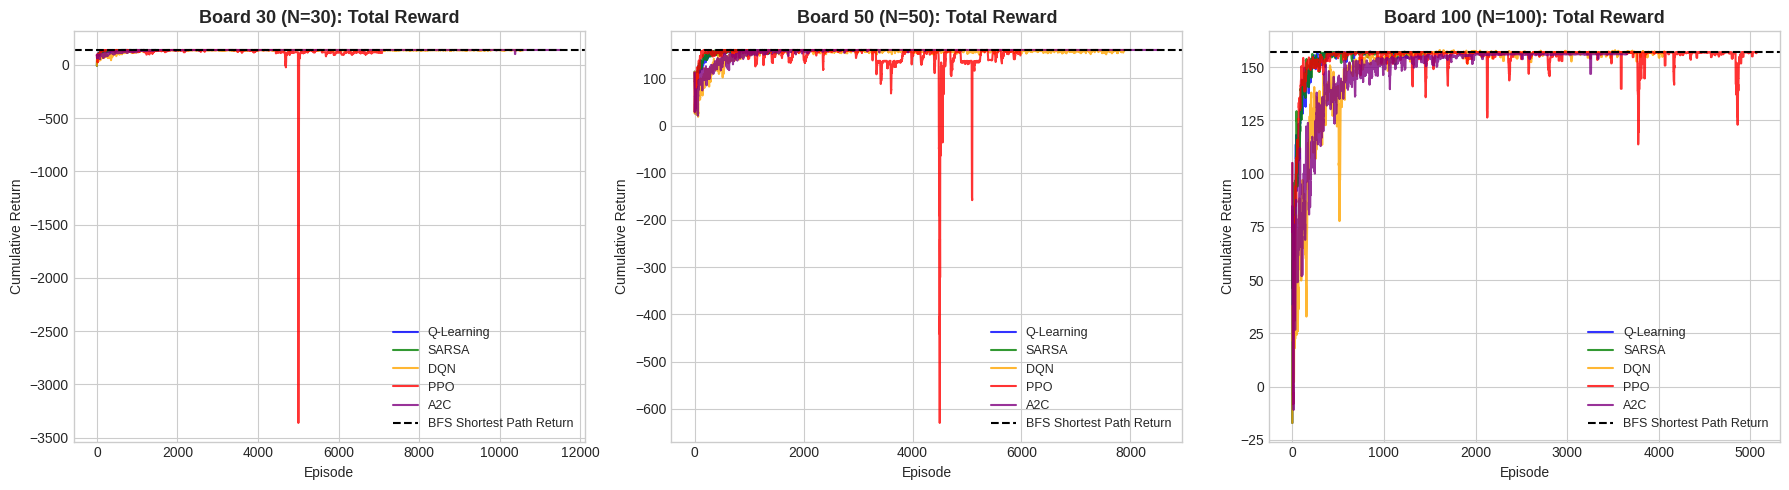

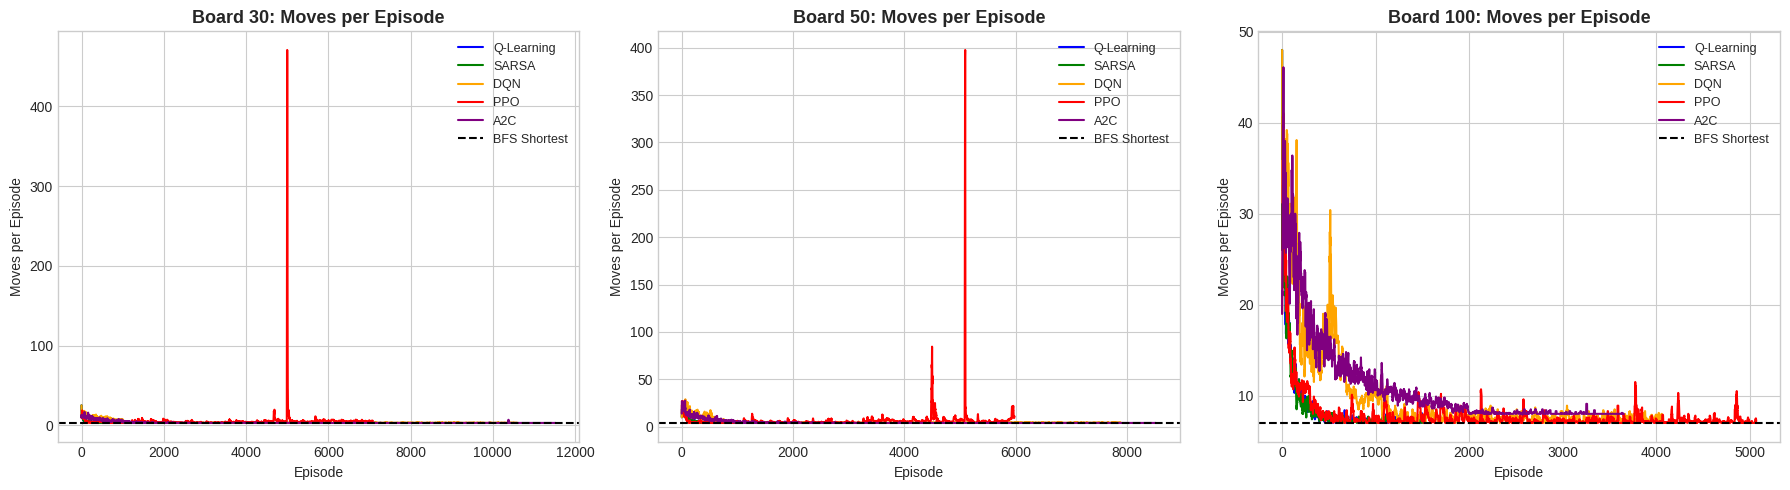

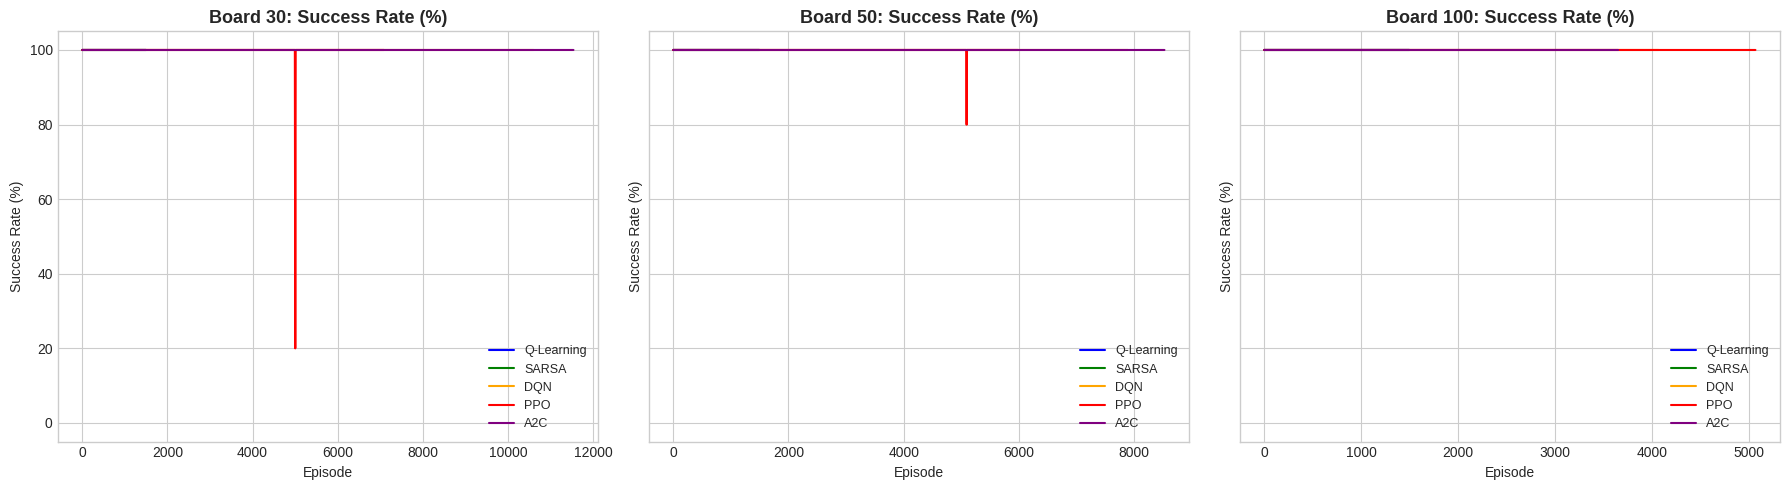

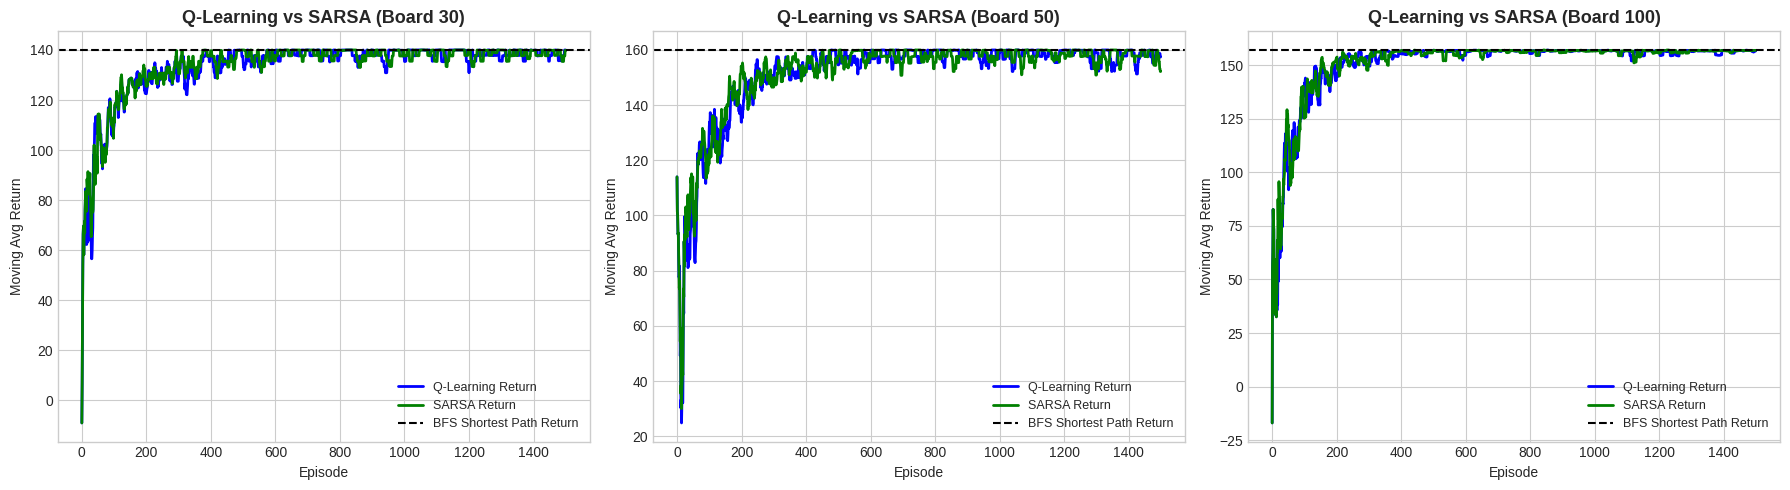

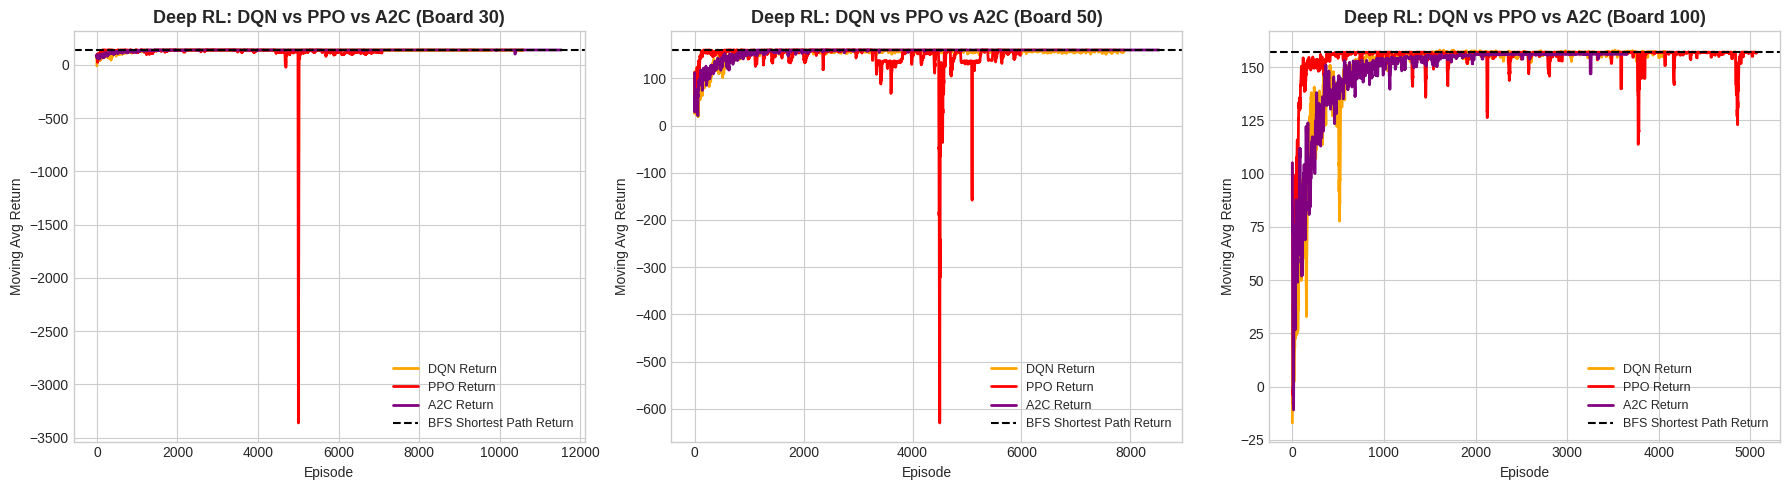

All 5 plots successfully saved to: /kaggle/working/artifacts


In [20]:
# Cell 16: Generate and Save All Required Plots
def smooth_series(series, window=10):
    return pd.Series(series).rolling(window, min_periods=1).mean().values

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# -------------------------------------------------------------
# Plot 1: Total Reward vs Training Episodes (Boards 30, 50, 100)
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
for idx, b in enumerate(BOARDS):
    ax = axes[idx]
    ax.plot(smooth_series(q_learning_histories[b]["rewards_history"]), label="Q-Learning", color="blue", alpha=0.8)
    ax.plot(smooth_series(sarsa_histories[b]["rewards_history"]), label="SARSA", color="green", alpha=0.8)
    if len(dqn_callbacks[b].episode_rewards) > 0:
        ax.plot(smooth_series(dqn_callbacks[b].episode_rewards), label="DQN", color="orange", alpha=0.8)
    if len(ppo_callbacks[b].episode_rewards) > 0:
        ax.plot(smooth_series(ppo_callbacks[b].episode_rewards), label="PPO", color="red", alpha=0.8)
    if len(a2c_callbacks[b].episode_rewards) > 0:
        ax.plot(smooth_series(a2c_callbacks[b].episode_rewards), label="A2C", color="purple", alpha=0.8)
    ax.axhline(bfs_results[b].total_reward, color="black", linestyle="--", label="BFS Shortest Path Return")
    ax.set_title(f"Board {b} (N={b}): Total Reward", fontsize=13, fontweight="bold")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Cumulative Return")
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
p1 = os.path.join(ARTIFACTS_DIR, "total_reward_vs_episodes.png")
plt.savefig(p1, dpi=300)
plt.show()

# -------------------------------------------------------------
# Plot 2: Average Moves vs Training Episodes
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
for idx, b in enumerate(BOARDS):
    ax = axes[idx]
    ax.plot(smooth_series(q_learning_histories[b]["moves_history"]), label="Q-Learning", color="blue")
    ax.plot(smooth_series(sarsa_histories[b]["moves_history"]), label="SARSA", color="green")
    if len(dqn_callbacks[b].episode_moves) > 0:
        ax.plot(smooth_series(dqn_callbacks[b].episode_moves), label="DQN", color="orange")
    if len(ppo_callbacks[b].episode_moves) > 0:
        ax.plot(smooth_series(ppo_callbacks[b].episode_moves), label="PPO", color="red")
    if len(a2c_callbacks[b].episode_moves) > 0:
        ax.plot(smooth_series(a2c_callbacks[b].episode_moves), label="A2C", color="purple")
    ax.axhline(bfs_results[b].shortest_path_length, color="black", linestyle="--", label="BFS Shortest")
    ax.set_title(f"Board {b}: Moves per Episode", fontsize=13, fontweight="bold")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Moves per Episode")
    ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
p2 = os.path.join(ARTIFACTS_DIR, "avg_moves_vs_episodes.png")
plt.savefig(p2, dpi=300)
plt.show()

# -------------------------------------------------------------
# Plot 3: Success Rate vs Training Episodes
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for idx, b in enumerate(BOARDS):
    ax = axes[idx]
    ax.plot(smooth_series(q_learning_histories[b]["success_history"]) * 100, label="Q-Learning", color="blue")
    ax.plot(smooth_series(sarsa_histories[b]["success_history"]) * 100, label="SARSA", color="green")
    if len(dqn_callbacks[b].episode_success) > 0:
        ax.plot(smooth_series(dqn_callbacks[b].episode_success) * 100, label="DQN", color="orange")
    if len(ppo_callbacks[b].episode_success) > 0:
        ax.plot(smooth_series(ppo_callbacks[b].episode_success) * 100, label="PPO", color="red")
    if len(a2c_callbacks[b].episode_success) > 0:
        ax.plot(smooth_series(a2c_callbacks[b].episode_success) * 100, label="A2C", color="purple")
    ax.set_title(f"Board {b}: Success Rate (%)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Success Rate (%)")
    ax.set_ylim(-5, 105)
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
p3 = os.path.join(ARTIFACTS_DIR, "success_rate_vs_episodes.png")
plt.savefig(p3, dpi=300)
plt.show()

# -------------------------------------------------------------
# Plot 4: Q-Learning vs SARSA Detailed Comparison
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, b in enumerate(BOARDS):
    ax = axes[idx]
    ax.plot(smooth_series(q_learning_histories[b]["rewards_history"]), label="Q-Learning Return", color="blue", linewidth=2)
    ax.plot(smooth_series(sarsa_histories[b]["rewards_history"]), label="SARSA Return", color="green", linewidth=2)
    ax.axhline(bfs_results[b].total_reward, color="black", linestyle="--", label="BFS Shortest Path Return")
    ax.set_title(f"Q-Learning vs SARSA (Board {b})", fontsize=13, fontweight="bold")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Moving Avg Return")
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
p4 = os.path.join(ARTIFACTS_DIR, "q_learning_vs_sarsa.png")
plt.savefig(p4, dpi=300)
plt.show()

# -------------------------------------------------------------
# Plot 5: DQN vs PPO vs A2C Detailed Comparison
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, b in enumerate(BOARDS):
    ax = axes[idx]
    if len(dqn_callbacks[b].episode_rewards) > 0:
        ax.plot(smooth_series(dqn_callbacks[b].episode_rewards), label="DQN Return", color="orange", linewidth=2)
    if len(ppo_callbacks[b].episode_rewards) > 0:
        ax.plot(smooth_series(ppo_callbacks[b].episode_rewards), label="PPO Return", color="red", linewidth=2)
    if len(a2c_callbacks[b].episode_rewards) > 0:
        ax.plot(smooth_series(a2c_callbacks[b].episode_rewards), label="A2C Return", color="purple", linewidth=2)
    ax.axhline(bfs_results[b].total_reward, color="black", linestyle="--", label="BFS Shortest Path Return")
    ax.set_title(f"Deep RL: DQN vs PPO vs A2C (Board {b})", fontsize=13, fontweight="bold")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Moving Avg Return")
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
p5 = os.path.join(ARTIFACTS_DIR, "dqn_vs_ppo_vs_a2c.png")
plt.savefig(p5, dpi=300)
plt.show()

print("All 5 plots successfully saved to:", ARTIFACTS_DIR)


In [21]:
# Cell 17: Compact Results Summary Table
rows = []

for b in BOARDS:
    # 1. Deterministic BFS Baseline
    bfs_res = bfs_results[b]
    rows.append({
        "Board": f"Board {b}",
        "Algorithm": "BFS (Optimal Baseline)",
        "Avg Moves": f"{bfs_res.shortest_path_length:.1f}",
        "Success Rate (%)": "100.0%",
        "Avg Cumulative Reward": f"{bfs_res.total_reward:+.1f}",
        "Convergence Episode": "N/A (Analytical)",
    })
    
    # 2. Q-Learning
    ql = q_learning_results[b]
    rows.append({
        "Board": f"Board {b}",
        "Algorithm": "Tabular Q-Learning",
        "Avg Moves": f"{ql['avg_moves']:.2f}",
        "Success Rate (%)": f"{ql['success_rate']:.1f}%",
        "Avg Cumulative Reward": f"{ql['avg_reward']:+.2f}",
        "Convergence Episode": str(ql['convergence_episode']),
    })
    
    # 3. SARSA
    sa = sarsa_results[b]
    rows.append({
        "Board": f"Board {b}",
        "Algorithm": "Tabular SARSA",
        "Avg Moves": f"{sa['avg_moves']:.2f}",
        "Success Rate (%)": f"{sa['success_rate']:.1f}%",
        "Avg Cumulative Reward": f"{sa['avg_reward']:+.2f}",
        "Convergence Episode": str(sa['convergence_episode']),
    })
    
    # 4. DQN
    dq = dqn_results[b]
    rows.append({
        "Board": f"Board {b}",
        "Algorithm": "SB3 DQN",
        "Avg Moves": f"{dq['avg_moves']:.2f}",
        "Success Rate (%)": f"{dq['success_rate']:.1f}%",
        "Avg Cumulative Reward": f"{dq['avg_reward']:+.2f}",
        "Convergence Episode": str(dq['convergence_episode']),
    })
    
    # 5. PPO
    pp = ppo_results[b]
    rows.append({
        "Board": f"Board {b}",
        "Algorithm": "SB3 PPO",
        "Avg Moves": f"{pp['avg_moves']:.2f}",
        "Success Rate (%)": f"{pp['success_rate']:.1f}%",
        "Avg Cumulative Reward": f"{pp['avg_reward']:+.2f}",
        "Convergence Episode": str(pp['convergence_episode']),
    })
    
    # 6. A2C
    ac = a2c_results[b]
    rows.append({
        "Board": f"Board {b}",
        "Algorithm": "SB3 A2C",
        "Avg Moves": f"{ac['avg_moves']:.2f}",
        "Success Rate (%)": f"{ac['success_rate']:.1f}%",
        "Avg Cumulative Reward": f"{ac['avg_reward']:+.2f}",
        "Convergence Episode": str(ac['convergence_episode']),
    })

summary_df = pd.DataFrame(rows)
summary_df["Convergence Episode"] = summary_df["Convergence Episode"].replace("None", "Not Converged")
run_mode = "Smoke Test" if SMOKE_TEST else "Full Run"
summary_df.insert(0, "Run Mode", run_mode)

# Save summary to artifacts CSV
summary_csv = os.path.join(ARTIFACTS_DIR, "results_summary.csv")
summary_df.to_csv(summary_csv, index=False)

print("\n" + "=" * 90)
print(f"SMART DICE RL BENCHMARK SUMMARY ({run_mode})")
print("=" * 90)
try:
    from tabulate import tabulate
    print(tabulate(summary_df, headers="keys", tablefmt="github", showindex=False))
except ImportError:
    print(summary_df.to_string(index=False))
print("=" * 90)
print(f"Summary table saved to: {summary_csv}")



SMART DICE RL BENCHMARK SUMMARY (Full Run)
| Run Mode   | Board     | Algorithm              |   Avg Moves | Success Rate (%)   |   Avg Cumulative Reward | Convergence Episode   |
|------------|-----------|------------------------|-------------|--------------------|-------------------------|-----------------------|
| Full Run   | Board 30  | BFS (Optimal Baseline) |           3 | 100.0%             |                     140 | N/A (Analytical)      |
| Full Run   | Board 30  | Tabular Q-Learning     |           3 | 100.0%             |                     140 | 30                    |
| Full Run   | Board 30  | Tabular SARSA          |           3 | 100.0%             |                     140 | 35                    |
| Full Run   | Board 30  | SB3 DQN                |           3 | 100.0%             |                     140 | 870                   |
| Full Run   | Board 30  | SB3 PPO                |           5 | 100.0%             |                     119 | 75                   